# Credit risk: from raw tables to a scored model

This notebook tells the story of the project in one pass: the question, how the models are scored, what moved the score, what did not, what the model uses, where it fails, and the final holdout result.

It reads only the result files in `results/` and the charts in `docs/img/`, so it runs in seconds without the Kaggle data or the database. Run it from the project root. The full code, the maths and the write-up are in `src/`, `MATH.md`, `results.md` and `MODEL_CARD.md`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

RES = Path("results")
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8985"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1",
})
pd.set_option("display.width", 160)

## 1. The question

Which loan applicants will default? The data is Home Credit Default Risk: 307,511 loan applications, of which 8.07% defaulted, plus six tables of credit history (credit bureau, previous applications, instalments, credit cards).

Only 8% default, so a model that says "nobody defaults" is right 92% of the time and useless. Accuracy is therefore not used. The main metric is **PR-AUC** (area under the precision-recall curve), whose floor is the default rate itself, with ROC-AUC and log loss alongside.

The two floors every model has to beat: predicting the base rate for everyone, and a one-feature model on the mean of the three external credit scores (`EXT_SOURCE`).

In [2]:
baselines = pd.read_csv(RES / "baselines.csv")
floors = baselines[baselines.metric.isin(["pr_auc", "roc_auc", "log_loss"])].pivot(index="model", columns="metric", values="mean")
floors[["pr_auc", "roc_auc", "log_loss"]].round(4)

metric,pr_auc,roc_auc,log_loss
model,,,
"EXT_SOURCE mean, logistic",0.1889,0.7164,0.2577
base rate for everyone,0.0807,0.5000,0.2805


## 2. How the models are scored

Everything is compared on the same 5 stratified folds of the 246,008 training applicants, with the 61,503 holdout applicants kept untouched until the end. Every fitting step (imputation, clipping, scaling, encoding) is fitted inside the training fold only, and one evaluation function, checked against scikit-learn, scores every model. The chart shows the two floors as ROC and precision-recall curves.

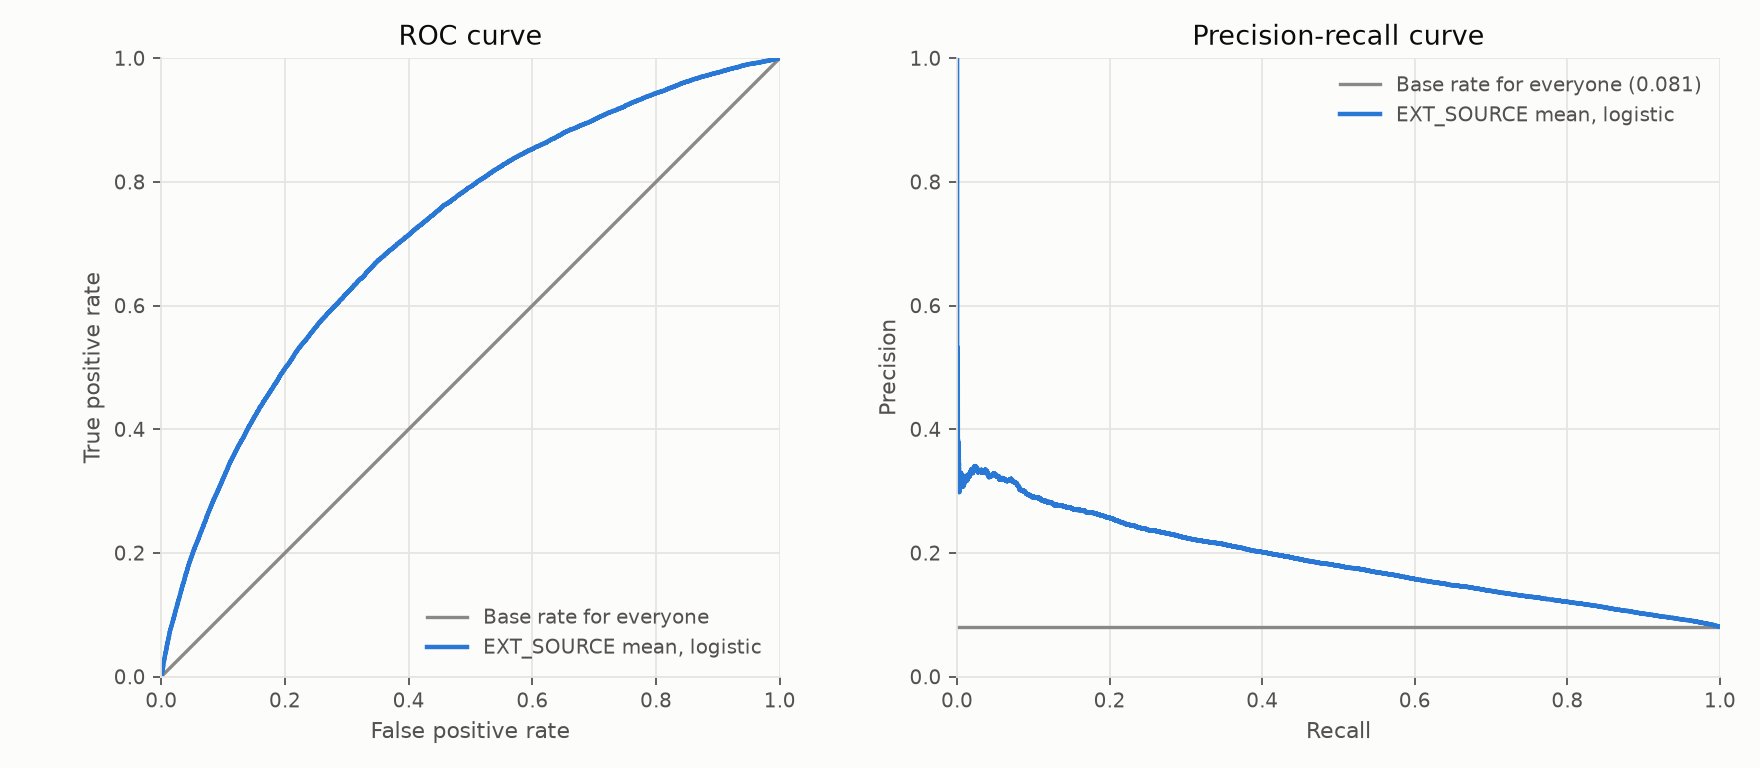

In [3]:
display(Image(filename="docs/img/baseline_curves.png", width=820))

## 3. The model ladder

The same folds for every model, mean and standard deviation of PR-AUC over the folds. Orange models use the application columns only; blue models also use the 106 columns built in SQL from the other six tables.

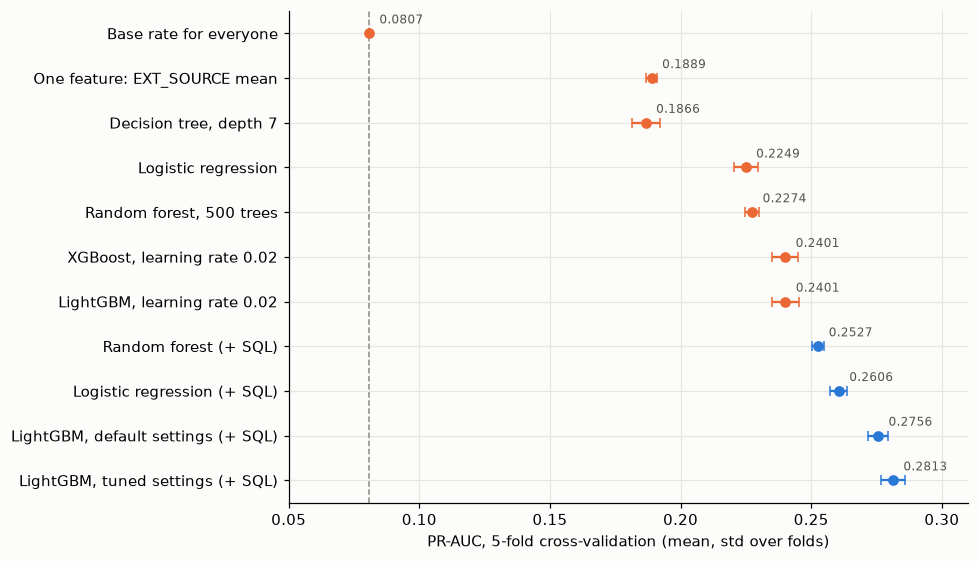

,model,columns,pr_auc,std
0,Base rate for everyone,application,0.0807,0.0000
1,One feature: EXT_SOURCE mean,application,0.1889,0.0021
2,"Decision tree, depth 7",application,0.1866,0.0053
3,Logistic regression,application,0.2249,0.0045
4,"Random forest, 500 trees",application,0.2274,0.0026
5,"XGBoost, learning rate 0.02",application,0.2401,0.0050
6,"LightGBM, learning rate 0.02",application,0.2401,0.0052
7,Random forest,sql,0.2527,0.0023
8,Logistic regression,sql,0.2606,0.0032
9,"LightGBM, default settings",sql,0.2756,0.0039


In [4]:
def mean_std(values):
    return float(np.mean(values)), float(np.std(values, ddof=1))

def from_rows(frame, **conditions):
    for column, value in conditions.items():
        frame = frame[frame[column] == value]
    return mean_std(frame["pr_auc"])

base = baselines[baselines.metric == "pr_auc"].set_index("model")
tree = pd.read_csv(RES / "tree_depth.csv")
forest = pd.read_csv(RES / "forest.csv")
penalty = pd.read_csv(RES / "regularization_curve.csv")
xgb = pd.read_csv(RES / "xgboost_stopped.csv")
lgb = pd.read_csv(RES / "lightgbm_stopped.csv")
gain = pd.read_csv(RES / "feature_gain.csv")
forest_sql = pd.read_csv(RES / "forest_sql.csv")

ladder = [
    ("Base rate for everyone", "application", (base.loc["base rate for everyone", "mean"], 0.0)),
    ("One feature: EXT_SOURCE mean", "application", (base.loc["EXT_SOURCE mean, logistic", "mean"], base.loc["EXT_SOURCE mean, logistic", "std"])),
    ("Decision tree, depth 7", "application", from_rows(tree, max_depth=7, split="validation")),
    ("Logistic regression", "application", from_rows(penalty, penalty="L2", C=0.03, split="validation")),
    ("Random forest, 500 trees", "application", from_rows(forest, experiment="trees", setting=500, split="validation")),
    ("XGBoost, learning rate 0.02", "application", from_rows(xgb, learning_rate=0.02)),
    ("LightGBM, learning rate 0.02", "application", from_rows(lgb, learning_rate=0.02)),
    ("Random forest", "sql", from_rows(forest_sql, max_features=30)),
    ("Logistic regression", "sql", from_rows(gain, model="logistic", config="all groups")),
    ("LightGBM, default settings", "sql", from_rows(gain, model="lightgbm", config="all groups")),
    ("LightGBM, tuned settings", "sql", from_rows(gain, model="lightgbm", config="all groups, tuned")),
]
table = pd.DataFrame([(name, kind, m, s) for name, kind, (m, s) in ladder], columns=["model", "columns", "pr_auc", "std"])

fig, ax = plt.subplots(figsize=(9, 5.2))
for i, row in table.iloc[::-1].reset_index(drop=True).iterrows():
    color = BLUE if row["columns"] == "sql" else ORANGE
    ax.errorbar(row["pr_auc"], i, xerr=row["std"], marker="o", color=color, capsize=3)
    ax.text(row["pr_auc"] + 0.004, i + 0.22, f"{row['pr_auc']:.4f}", fontsize=8, color="#52514e")
labels = [f"{n} (+ SQL)" if k == "sql" else n for n, k in zip(table["model"], table["columns"])]
ax.set_yticks(range(len(table)), labels[::-1])
ax.set(xlabel="PR-AUC, 5-fold cross-validation (mean, std over folds)", xlim=(0.05, 0.31))
ax.axvline(0.0807, color=GREY, linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()
table.round(4)

Boosting beats the forest and logistic regression on the same columns, LightGBM and XGBoost give the same scores, and a decision tree overfits (its training PR-AUC reaches 1.0 at full depth while the validation score falls). The biggest jump is not the model but the features, next.

## 4. Features built in SQL

Each group of columns (credit bureau, previous applications, POS cash, instalments, credit cards, ratios of the application columns) is added to the application columns on its own, and then all six together. The bars show the gain in PR-AUC for LightGBM over the application columns only, with the standard deviation of the fold-by-fold difference.

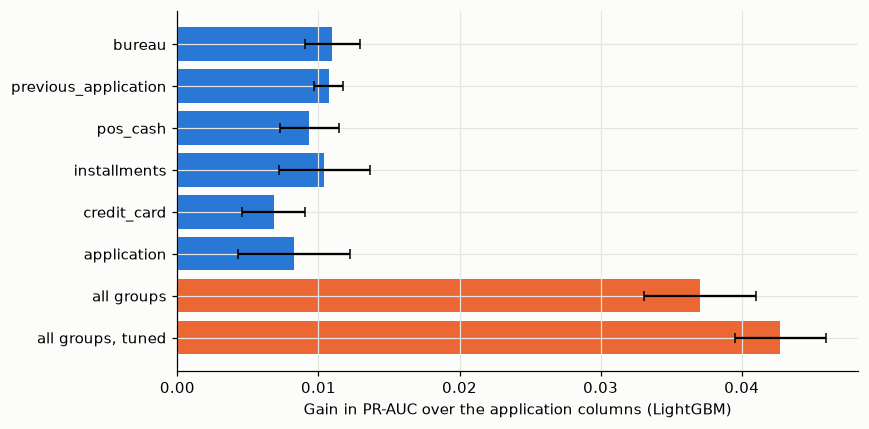

,config,gain,std,folds_better
0,bureau,0.0110,0.0019,5
1,previous_application,0.0107,0.0010,5
2,pos_cash,0.0094,0.0021,5
3,installments,0.0104,0.0033,5
4,credit_card,0.0068,0.0022,5
5,application,0.0083,0.0040,5
6,all groups,0.0371,0.0040,5
7,"all groups, tuned",0.0427,0.0032,5


In [5]:
lg = gain[gain.model == "lightgbm"]
reference = lg[lg.config == "base"].set_index("fold")["pr_auc"]
rows = []
for config, part in lg.groupby("config", sort=False):
    if config == "base":
        continue
    difference = part.set_index("fold")["pr_auc"] - reference
    rows.append({"config": config, "gain": difference.mean(), "std": difference.std(ddof=1), "folds_better": int((difference > 0).sum())})
sql = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 4))
colors = [BLUE if "tuned" not in c and c != "all groups" else ORANGE for c in sql["config"]]
ax.barh(sql["config"][::-1], sql["gain"][::-1], xerr=sql["std"][::-1], color=colors[::-1], capsize=3)
ax.set(xlabel="Gain in PR-AUC over the application columns (LightGBM)")
plt.tight_layout()
plt.show()
sql.round(4)

Every group improves PR-AUC in all 5 folds, and the six together add about 0.037. Tuning the settings (60 trials with Optuna) adds a further 0.006, which is small next to the features.

## 5. What did not help

**Class imbalance.** Class weights, undersampling, oversampling and SMOTE are compared with doing nothing. None improves the ranking beyond fold-to-fold noise, and the methods that reweight the classes ruin the probabilities (the mean predicted probability jumps from 0.08 to about 0.40) until the odds shift is undone.

In [6]:
imbalance = pd.read_csv(RES / "imbalance.csv")
(imbalance.groupby(["model", "method"], sort=False)[["pr_auc", "log_loss", "log_loss_corrected", "mean_probability"]].mean().round(4))

pr_auc  log_loss  log_loss_corrected  mean_probability
model    method                                                              
logistic none          0.2250    0.2495              0.2495            0.0808
         class_weight  0.2231    0.5919              0.2496            0.4204
         undersample   0.2213    0.5951              0.2501            0.4226
         oversample    0.2226    0.5918              0.2497            0.4201
         smote         0.2197    0.5809              0.2526            0.4020
lightgbm none          0.2386    0.2470              0.2470            0.0804
         class_weight  0.2386    0.5584              0.2475            0.4008
         undersample   0.2308    0.5902              0.2483            0.4221
         oversample    0.2393    0.5581              0.2474            0.4010
         smote         0.2355    0.2475              0.3594            0.0849

**Calibration.** Logistic regression and LightGBM trained on log loss already give calibrated probabilities (expected calibration error 0.003), so Platt scaling and isotonic regression change nothing for them. The random forest is not calibrated until Platt scaling is applied.

In [7]:
calibration = pd.read_csv(RES / "calibration.csv")
(calibration.groupby(["model", "calibrator"], sort=False)[["pr_auc", "log_loss", "ece"]].mean().round(4))

pr_auc  log_loss     ece
model             calibrator                          
logistic          none        0.2246    0.2496  0.0025
                  platt       0.2246    0.2496  0.0026
                  isotonic    0.2175    0.2512  0.0031
lightgbm          none        0.2357    0.2477  0.0035
                  platt       0.2357    0.2476  0.0032
                  isotonic    0.2278    0.2491  0.0029
lightgbm_weighted none        0.2363    0.5584  0.3205
                  platt       0.2363    0.2475  0.0038
                  isotonic    0.2269    0.2488  0.0040
forest            none        0.2256    0.2518  0.0129
                  platt       0.2256    0.2501  0.0027
                  isotonic    0.2177    0.2517  0.0039

## 6. From a probability to a decision

Refusing a loan has a cost, and so does approving one that defaults. With an assumed cost (a missed default loses 45% of the credit amount, a refused good loan a 10% margin, so the ratio is 4.5, weighted by loan size), the cheapest threshold on calibrated probabilities is 1 / (1 + 4.5) = 0.182. The cost figures are assumptions, not data, and the chart shows how much the answer depends on them: a flat ratio of 10 moves the best threshold to 0.09. The curves are for the LightGBM on the application columns.

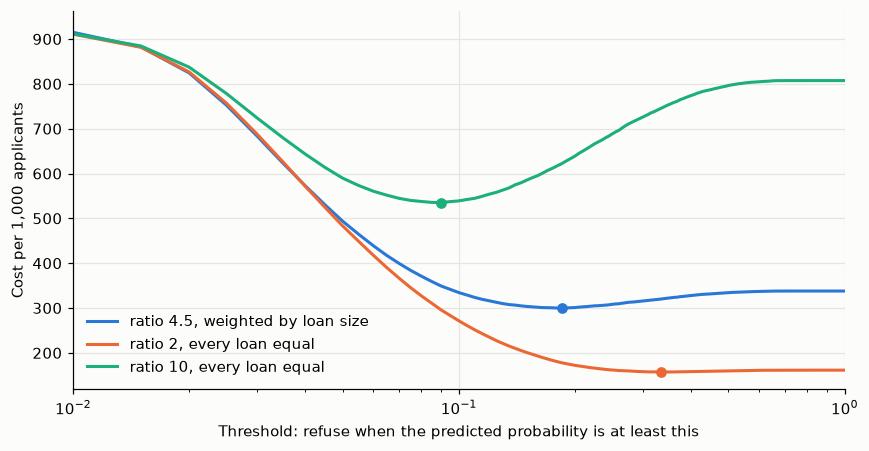

In [8]:
curve = pd.read_csv(RES / "threshold_curve.csv")
curve = curve[(curve.scoring == "lightgbm") & curve.scheme.isin(["amount", "flat_10", "flat_2"])]
fig, ax = plt.subplots(figsize=(8, 4.2))
labels = {"amount": "ratio 4.5, weighted by loan size", "flat_10": "ratio 10, every loan equal", "flat_2": "ratio 2, every loan equal"}
for color, (scheme, part) in zip([BLUE, ORANGE, GREEN], curve.groupby("scheme", sort=False)):
    ax.plot(part["threshold"], part["cost_per_1000"], color=color, label=labels[scheme], linewidth=2)
    best = part.loc[part["cost_per_1000"].idxmin()]
    ax.plot(best["threshold"], best["cost_per_1000"], "o", color=color)
ax.set(xscale="log", xlim=(0.01, 1), xlabel="Threshold: refuse when the predicted probability is at least this", ylabel="Cost per 1,000 applicants")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 7. What the model uses

Two views of the same question for the best model (LightGBM with the six SQL groups, tuned): how much the PR-AUC falls when one column is shuffled, and the mean absolute SHAP value, which measures how far a column moves the predictions.

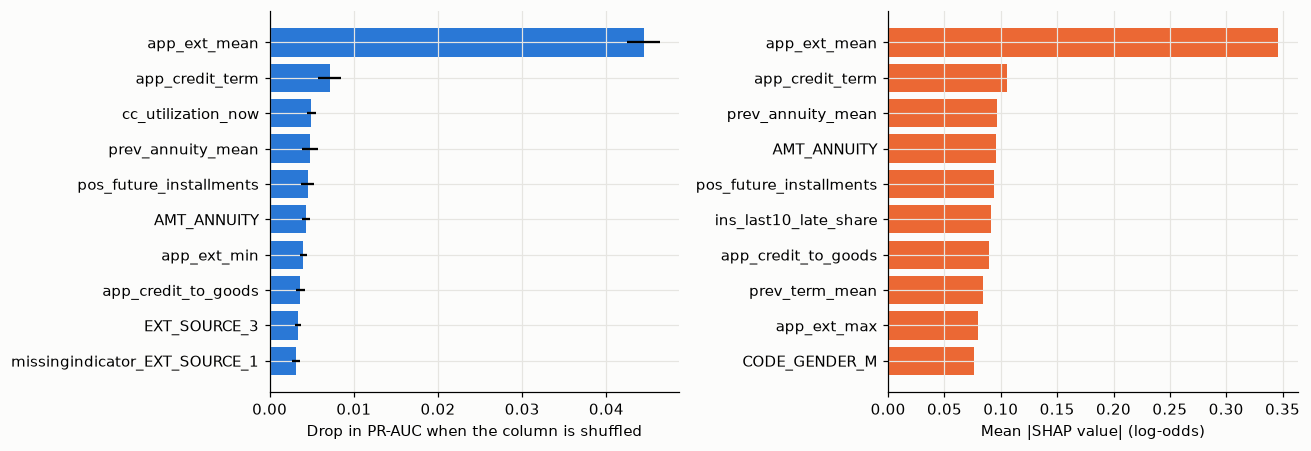

In [9]:
perm = pd.read_csv(RES / "permutation_importance.csv").head(10).iloc[::-1]
shap = pd.read_csv(RES / "shap_importance.csv").head(10).iloc[::-1]
clean = lambda names: [n.split("__", 1)[-1] for n in names]
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.2))
a.barh(clean(perm["feature"]), perm["importance_mean"], xerr=perm["importance_std"], color=BLUE)
a.set(xlabel="Drop in PR-AUC when the column is shuffled")
b.barh(clean(shap["feature"]), shap["mean_abs_shap"], color=ORANGE)
b.set(xlabel="Mean |SHAP value| (log-odds)")
plt.tight_layout()
plt.show()

The mean of the three external credit scores (`app_ext_mean`) dominates both views: shuffling it costs about six times as much PR-AUC as the next column. The columns built in SQL account for roughly 63% of the total SHAP importance. Single applicants can be explained too:

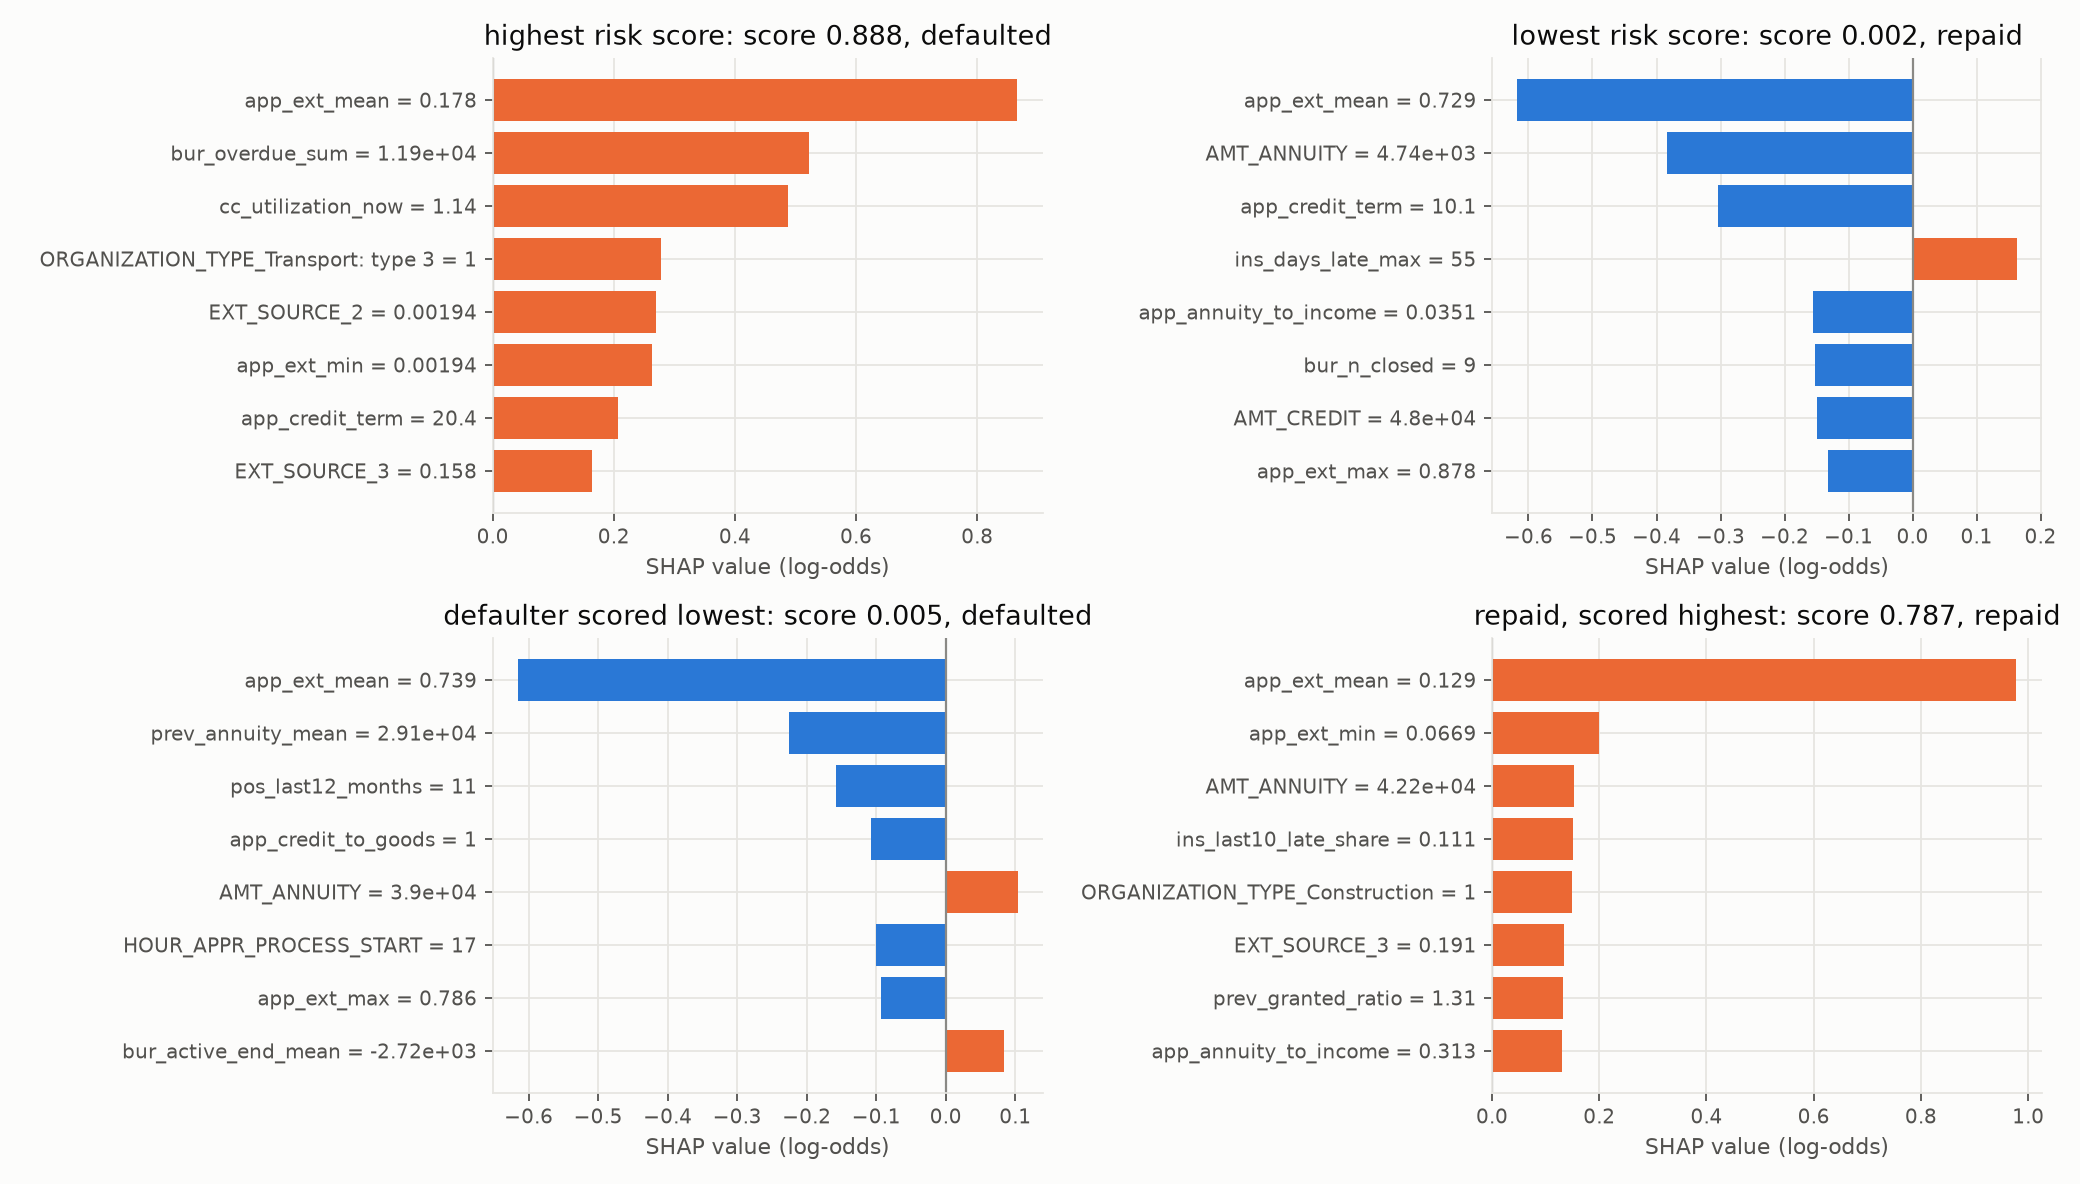

In [10]:
display(Image(filename="docs/img/shap_applicants.png", width=860))

## 8. Where the model fails

Out-of-fold predictions for all 246,008 training applicants, at the threshold 0.182. The model is calibrated in every segment of 1,000 applicants or more, so the differences below are in ranking quality (ROC-AUC with a 95% bootstrap interval) and in who gets refused.

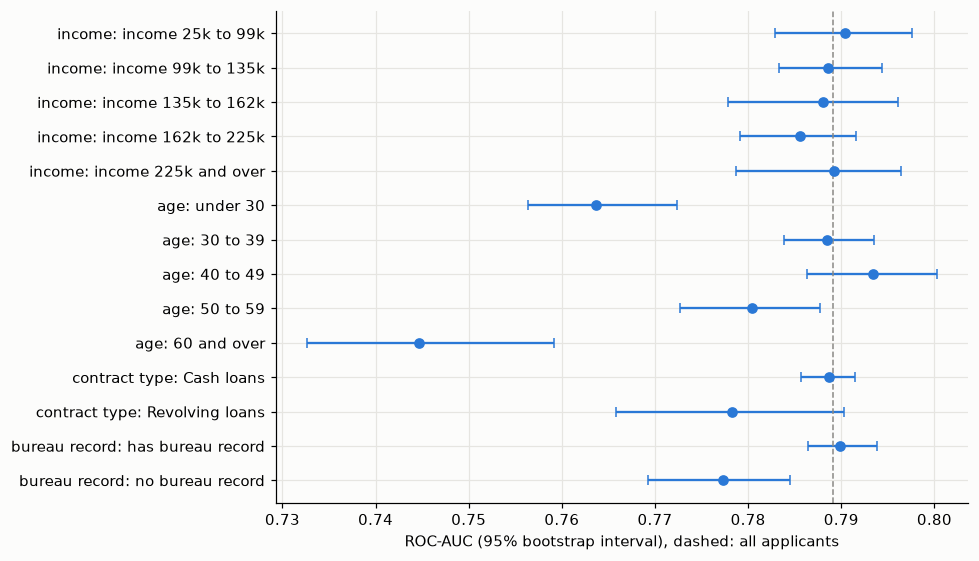

,family,segment,n,default_rate,roc_auc,fnr,fpr
0,income,income 25k to 99k,50973,0.083,0.790,0.580,0.087
1,income,income 99k to 135k,68587,0.086,0.789,0.583,0.095
2,income,income 135k to 162k,28502,0.086,0.788,0.577,0.093
3,income,income 162k to 225k,60316,0.081,0.786,0.608,0.081
4,income,income 225k and over,37630,0.065,0.789,0.683,0.060
5,age,under 30,36281,0.115,0.764,0.504,0.158
6,age,30 to 39,65844,0.096,0.788,0.551,0.113
7,age,40 to 49,61296,0.077,0.793,0.612,0.075
8,age,50 to 59,54477,0.061,0.780,0.704,0.047
9,age,60 and over,28110,0.049,0.745,0.823,0.024


In [11]:
seg = pd.read_csv(RES / "segments.csv")
overall = seg[seg.family == "all"].iloc[0]
view = seg[seg.family.isin(["income", "age", "contract type", "bureau record"])].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 5.2))
for i, row in view.iloc[::-1].reset_index(drop=True).iterrows():
    ax.errorbar(row["roc_auc"], i, xerr=[[row["roc_auc"] - row["roc_auc_low"]], [row["roc_auc_high"] - row["roc_auc"]]], marker="o", color=BLUE, capsize=3)
ax.set_yticks(range(len(view)), (view["family"] + ": " + view["segment"])[::-1])
ax.axvline(overall["roc_auc"], color=GREY, linestyle="--", linewidth=1)
ax.set(xlabel="ROC-AUC (95% bootstrap interval), dashed: all applicants")
plt.tight_layout()
plt.show()
view[["family", "segment", "n", "default_rate", "roc_auc", "fnr", "fpr"]].round(3)

Income and contract type barely change the ranking. Applicants aged 60 and over and under 30 are ranked worse than the rest, and applicants without a credit bureau record are ranked worse than those with one. `fnr` is the share of defaulters the threshold misses and `fpr` the share of good loans it refuses.

## 9. Fairness check

The model uses gender and age as inputs. The table compares the groups (out of fold, same threshold), and for gender also a model refitted without the gender column.

In [12]:
fair = pd.read_csv(RES / "fairness.csv")
fair["approved"] = 1 - fair["share_refused"]
fair["defaulters_refused"] = 1 - fair["fnr"]
fair["good_loans_refused"] = fair["fpr"]
shown = fair[(fair.model == "with gender") | (fair.family == "gender")]
(shown[["model", "family", "group", "n", "default_rate", "mean_probability", "approved", "defaulters_refused", "good_loans_refused"]].round(3).reset_index(drop=True))

,model,family,group,n,default_rate,mean_probability,approved,defaulters_refused,good_loans_refused
0,with gender,gender,men,84119,0.101,0.100,0.843,0.465,0.122
1,with gender,gender,women,161887,0.070,0.070,0.915,0.351,0.065
2,with gender,age,under 30,36281,0.115,0.115,0.803,0.496,0.158
3,with gender,age,30 to 39,65844,0.096,0.095,0.855,0.449,0.113
4,with gender,age,40 to 49,61296,0.077,0.076,0.902,0.388,0.075
5,with gender,age,50 to 59,54477,0.061,0.061,0.938,0.296,0.047
6,with gender,age,60 and over,28110,0.049,0.048,0.968,0.177,0.024
7,without gender,gender,men,84119,0.101,0.093,0.858,0.435,0.110
8,without gender,gender,women,161887,0.070,0.073,0.908,0.368,0.072


The scores are calibrated within every group (mean predicted probability matches the default rate), yet the error rates differ: 46.5% of men's defaulters are refused against 35.1% for women, and the gap between the youngest and oldest applicants is larger. Removing the gender column leaves the PR-AUC unchanged, narrows the gap without closing it, and breaks the calibration by gender. These results describe this model on this sample. They do not show that it is fair or unfair, and they say nothing about whether using these inputs is allowed in a given market.

## 10. The holdout, scored once

The 61,503 holdout applicants were scored a single time, after the scoring code, the settings and the threshold were committed. All models use the six SQL feature groups. Intervals are 95% bootstrap intervals over the holdout applicants.

In [13]:
hold = pd.read_csv(RES / "holdout.csv")
order = ["LightGBM", "logistic regression", "random forest", "EXT_SOURCE mean, logistic", "base rate"]
text = hold.assign(value=lambda d: d.apply(lambda r: f"{r['estimate']:.4f} ({r['low']:.4f} to {r['high']:.4f})", axis=1))
text.pivot(index="model", columns="metric", values="value").loc[order, ["pr_auc", "roc_auc", "log_loss"]]

metric,pr_auc,roc_auc,log_loss
model,,,
LightGBM,0.2957 (0.2835 to 0.3089),0.7918 (0.7852 to 0.7986),0.2347 (0.2303 to 0.2394)
logistic regression,0.2731 (0.2622 to 0.2860),0.7775 (0.7707 to 0.7845),0.2398 (0.2354 to 0.2446)
random forest,0.2605 (0.2491 to 0.2735),0.7690 (0.7617 to 0.7762),0.2440 (0.2398 to 0.2486)
"EXT_SOURCE mean, logistic",0.1921 (0.1825 to 0.2014),0.7165 (0.7083 to 0.7241),0.2574 (0.2528 to 0.2623)
base rate,0.0807 (0.0787 to 0.0828),0.5000 (0.5000 to 0.5000),0.2805 (0.2755 to 0.2856)


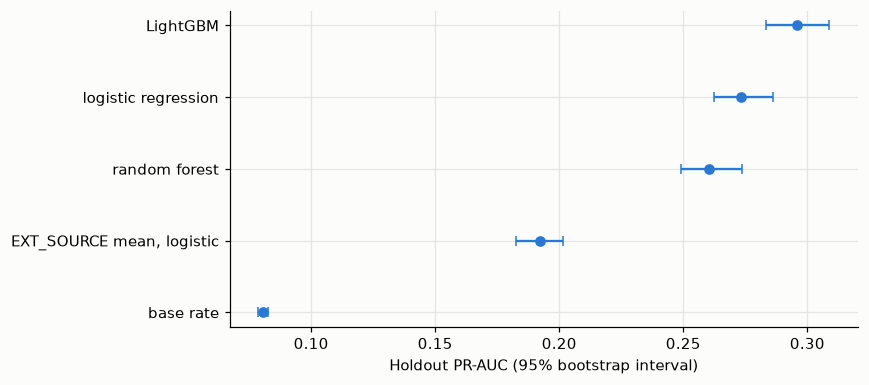

LightGBM at threshold 0.182: cost 277.9 per 1,000 applicants (269.0 to 287.1) against 338.8 for approving everybody, 18.0% less (16.3% to 19.6%); it refuses 11.0% of applicants and 41.0% of defaulters.


In [14]:
pr = hold[hold.metric == "pr_auc"].set_index("model").loc[order[::-1]]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.errorbar(pr["estimate"], range(len(pr)), xerr=[pr["estimate"] - pr["low"], pr["high"] - pr["estimate"]], fmt="o", color=BLUE, capsize=3)
ax.set_yticks(range(len(pr)), pr.index)
ax.set(xlabel="Holdout PR-AUC (95% bootstrap interval)")
plt.tight_layout()
plt.show()

cost = pd.read_csv(RES / "holdout_cost.csv").iloc[0]
print(f"LightGBM at threshold {cost.threshold:.3f}: cost {cost.cost_per_1000:.1f} per 1,000 applicants "
      f"({cost.cost_per_1000_low:.1f} to {cost.cost_per_1000_high:.1f}) against {cost.cost_refuse_nobody:.1f} for approving everybody, "
      f"{cost.saving:.1%} less ({cost.saving_low:.1%} to {cost.saving_high:.1%}); "
      f"it refuses {cost.share_refused:.1%} of applicants and {cost.defaulters_refused:.1%} of defaulters.")

LightGBM comes first, then logistic regression, then the forest, the one-feature model and the base rate: the same order as in cross-validation. Every model scores a little higher on the holdout than in cross-validation, and the reason was not isolated. The PR-AUC intervals of LightGBM and logistic regression overlap, so the holdout alone does not separate them.

## What this does not show

- The cost figures behind the threshold are assumptions, not Home Credit data.
- The data has no application dates, so the split is random and says nothing about change over time.
- The tuned settings were found on the application columns and reused with the SQL features.
- The model has not been served, monitored or checked on another lender's applicants.

See `results.md` for every result and everything that did not work, `MATH.md` for the maths and `MODEL_CARD.md` for the intended use and limits.